# Scam vs Legitimate SMS Classifier (Indian SMS)
**Dataset:** `binary_sms_30k.csv` (synthetic, 30,000 rows) with pre-made splits `binary_30k_train/val/test.csv`.
**Goal:** classify each SMS as `scam` or `legitimate`, prioritising scam recall while keeping false positives on legitimate messages low.

Pipeline: 1) load & validate, 2) EDA, 3) leakage check, 4) model selection with CV, 5) threshold tuning on validation, 6) final test evaluation, 7) error analysis & robustness, 8) save model.
Optional external check on real SMS (UCI) is at the end if the file is present.

In [1]:
import re, json, warnings
import numpy as np, pandas as pd
import matplotlib.pyplot as plt
import joblib
from sklearn.model_selection import StratifiedKFold, cross_validate
from sklearn.feature_extraction.text import TfidfVectorizer, CountVectorizer
from sklearn.pipeline import make_pipeline, make_union
from sklearn.linear_model import LogisticRegression
from sklearn.svm import LinearSVC
from sklearn.naive_bayes import MultinomialNB
from sklearn.metrics import (classification_report, confusion_matrix, precision_recall_curve,
                             average_precision_score, roc_auc_score, precision_score, recall_score, f1_score)
warnings.filterwarnings("ignore")
RANDOM_STATE = 42
np.random.seed(RANDOM_STATE)
pd.set_option("display.max_colwidth", 120)
print("libraries ready")

libraries ready


## 1. Load and validate the data

In [4]:
full = pd.read_csv("binary_sms_30k.csv")
train = pd.read_csv("binary_30k_train.csv")
val   = pd.read_csv("binary_30k_val.csv")
test  = pd.read_csv("binary_30k_test.csv")

print("shapes:", full.shape, train.shape, val.shape, test.shape)
print("columns:", list(full.columns))
print("nulls:\n", full.isna().sum())
print("exact duplicate texts:", full.TEXT.str.lower().str.strip().duplicated().sum())

# Check that splits are disjoint and cover the full data
ids_train, ids_val, ids_test = set(train.TEXT), set(val.TEXT), set(test.TEXT)
print("train/val overlap:", len(ids_train & ids_val), "| train/test overlap:", len(ids_train & ids_test))
print("split sizes sum to full:", len(train) + len(val) + len(test) == len(full))
for name, d in [("train", train), ("val", val), ("test", test)]:
    print(name, d.BINARY_LABEL.value_counts(normalize=True).round(3).to_dict())

shapes: (30000, 4) (21000, 5) (4500, 5) (4500, 5)
columns: ['TEXT', 'BINARY_LABEL', 'CATEGORY', 'SOURCE']
nulls:
 TEXT            0
BINARY_LABEL    0
CATEGORY        0
SOURCE          0
dtype: int64
exact duplicate texts: 0
train/val overlap: 0 | train/test overlap: 0
split sizes sum to full: True
train {'legitimate': 0.55, 'scam': 0.45}
val {'legitimate': 0.55, 'scam': 0.45}
test {'legitimate': 0.55, 'scam': 0.45}


## 2. Exploratory data analysis

In [5]:
full["len_chars"] = full.TEXT.str.len()
full["n_words"] = full.TEXT.str.split().str.len()
full["has_url"] = full.TEXT.str.contains(r"(https?://|www\.|bit\.ly|\.xyz|\.top|\.apk|\.club|\.click)", case=False, regex=True)
full["has_phone"] = full.TEXT.str.contains(r"\b[6-9]\d{9}\b|\b1[89]00\d{7}\b", regex=True)
full["has_otp_word"] = full.TEXT.str.contains(r"\botp\b|\bpin\b|\bcvv\b", case=False, regex=True)
full["is_upper"] = full.TEXT.str.isupper()

print(full.groupby("BINARY_LABEL")[["len_chars","n_words"]].describe().T.round(1))
print()
print(full.groupby("BINARY_LABEL")[["has_url","has_phone","has_otp_word","is_upper"]].mean().round(3))
print()
print(full.CATEGORY.value_counts())

BINARY_LABEL     legitimate     scam
len_chars count     16500.0  13500.0
          mean         88.0    104.6
          std          22.8     17.3
          min           1.0     62.0
          25%          75.0     92.0
          50%          89.0    103.0
          75%         102.0    117.0
          max         170.0    182.0
n_words   count     16500.0  13500.0
          mean         14.7     15.4
          std           4.2      2.9
          min           1.0      9.0
          25%          12.0     13.0
          50%          15.0     16.0
          75%          18.0     18.0
          max          29.0     26.0

              has_url  has_phone  has_otp_word  is_upper
BINARY_LABEL                                            
legitimate      0.231      0.109         0.163     0.075
scam            0.508      0.413         0.212     0.080

CATEGORY
otp                  3525
bank_txn             3433
bank_link_hardneg    3110
kyc_phish            2676
otp_pin_request      2457
de

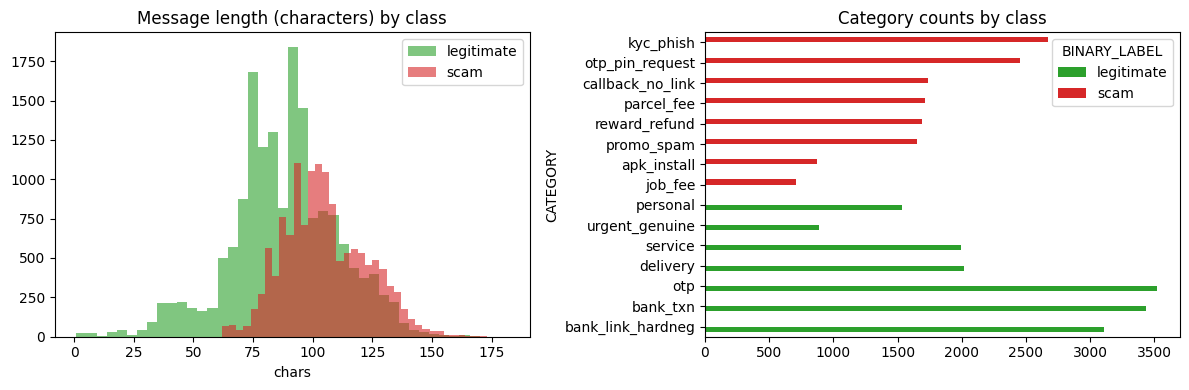

In [6]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
for lab, c in [("legitimate", "tab:green"), ("scam", "tab:red")]:
    axes[0].hist(full.loc[full.BINARY_LABEL == lab, "len_chars"], bins=40, alpha=0.6, label=lab, color=c)
axes[0].set_title("Message length (characters) by class"); axes[0].set_xlabel("chars"); axes[0].legend()

cat = full.groupby(["CATEGORY", "BINARY_LABEL"]).size().unstack(fill_value=0)
cat.sort_values("scam", ascending=True).plot.barh(ax=axes[1], color=["tab:green", "tab:red"])
axes[1].set_title("Category counts by class")
plt.tight_layout(); plt.show()

In [8]:
# Most discriminative words per class (log-odds of document frequency, legit vs scam)
cv = CountVectorizer(ngram_range=(1, 2), min_df=20, binary=True, lowercase=True)
X = cv.fit_transform(train.TEXT)
y = (train.BINARY_LABEL == "scam").values
vocab = np.array(cv.get_feature_names_out())
p_scam = np.asarray(X[y].mean(axis=0)).ravel() + 1e-3
p_leg  = np.asarray(X[~y].mean(axis=0)).ravel() + 1e-3
log_odds = np.log(p_scam / p_leg)
top_scam = vocab[np.argsort(-log_odds)[:25]]
top_leg  = vocab[np.argsort(log_odds)[:25]]
print("Scam-indicative terms:", list(top_scam))
print("Legitimate-indicative terms:", list(top_leg))

Scam-indicative terms: ['http', 'claim', 'verify', 'now http', 'now', 'pay rs', 'and', 'receive', 'to receive', 'ly', 'bit', 'bit ly', 'pan', 'the otp', 'is blocked', 'pm', 'club', 'at http', 'pending', 'reward', 'secure', 'click', 'now to', 'share the', 'suspicious']
Legitimate-indicative terms: ['https', 'www', 'https www', 'at https', 'com', 'otp for', 'request', 'mins', 'not share', 'your otp', 'is your', 'password', 'txn', 'debited', 'credited', 'gov', 'gov in', '10', 'payment', 'payment of', 'expected', 'track', 'ending', 'card ending', 'days']


**EDA takeaways so far:** the classes differ in length and vocabulary, and URLs and phone numbers appear in both classes (hard negatives are present). Next we check whether the simple flags alone explain the labels; if they do, the model would be learning shortcuts.

## 3. Leakage check: do simple flags explain the labels?

In [9]:
from sklearn.tree import DecisionTreeClassifier
flags = ["has_url", "has_phone", "has_otp_word", "is_upper"]
tr_f = pd.read_csv("binary_30k_train.csv")
def add_flags(d):
    d = d.copy()
    d["has_url"] = d.TEXT.str.contains(r"(https?://|www\.|bit\.ly|\.xyz|\.top|\.apk|\.club|\.click)", case=False, regex=True).astype(int)
    d["has_phone"] = d.TEXT.str.contains(r"\b[6-9]\d{9}\b|\b1[89]00\d{7}\b", regex=True).astype(int)
    d["has_otp_word"] = d.TEXT.str.contains(r"\botp\b|\bpin\b|\bcvv\b", case=False, regex=True).astype(int)
    d["is_upper"] = d.TEXT.str.isupper().astype(int)
    return d
tr_f, va_f = add_flags(train), add_flags(val)
flag_model = DecisionTreeClassifier(max_depth=4, random_state=RANDOM_STATE).fit(tr_f[flags], tr_f.BINARY_LABEL)
pred = flag_model.predict(va_f[flags])
print("Flags-only validation macro-F1:", round(f1_score(va_f.BINARY_LABEL, pred, average="macro"), 3))
print("Flags-only accuracy:", round((pred == va_f.BINARY_LABEL).mean(), 3))
print("A high score here would mean the labels are explained by flags alone (shortcut risk).")

Flags-only validation macro-F1: 0.826
Flags-only accuracy: 0.826
A high score here would mean the labels are explained by flags alone (shortcut risk).


## 4. Model selection
Candidates use text features only, so the same model can run on-device from raw SMS text. We compare with 5-fold stratified CV on the training split, scored with PR-AUC for the `scam` class (appropriate because scam is the positive, minority-leaning class).

In [11]:
y_train = (train.BINARY_LABEL == "scam").astype(int)
y_val   = (val.BINARY_LABEL == "scam").astype(int)
y_test  = (test.BINARY_LABEL == "scam").astype(int)

def char_word_features():
    return make_union(
        TfidfVectorizer(analyzer="char_wb", ngram_range=(2, 5), min_df=2, sublinear_tf=True, lowercase=True),
        TfidfVectorizer(analyzer="word", ngram_range=(1, 2), min_df=2, sublinear_tf=True, token_pattern=r"(?u)\b\w+\b|[^\w\s]"),
    )

candidates = {
    "NB_word_counts": make_pipeline(CountVectorizer(ngram_range=(1, 2), min_df=2), MultinomialNB(alpha=0.5)),
    "LR_word_tfidf": make_pipeline(TfidfVectorizer(ngram_range=(1, 2), min_df=2, sublinear_tf=True), LogisticRegression(max_iter=2000, C=5, class_weight="balanced")),
    "LinearSVC_char_word": make_pipeline(char_word_features(), LinearSVC(C=0.5, class_weight="balanced")),
    "LR_char_word": make_pipeline(char_word_features(), LogisticRegression(max_iter=3000, C=5, class_weight="balanced")),
}

skf = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)
rows = []
for name, pipe in candidates.items():
    res = cross_validate(pipe, train.TEXT, y_train, cv=skf,
                         scoring={"pr_auc": "average_precision", "f1": "f1", "recall": "recall", "precision": "precision"}, n_jobs=-1)
    rows.append({"model": name,
                 "PR-AUC": res["test_pr_auc"].mean(), "PR-AUC_sd": res["test_pr_auc"].std(),
                 "F1_scam": res["test_f1"].mean(), "recall_scam": res["test_recall"].mean(), "precision_scam": res["test_precision"].mean()})
cv_results = pd.DataFrame(rows).sort_values("PR-AUC", ascending=False).round(4)
cv_results

,model,PR-AUC,PR-AUC_sd,F1_scam,recall_scam,precision_scam
0,NB_word_counts,1.0,0.0,1.0,1.0,1.0
1,LR_word_tfidf,1.0,0.0,1.0,1.0,1.0
2,LinearSVC_char_word,1.0,0.0,1.0,1.0,1.0
3,LR_char_word,1.0,0.0,1.0,1.0,1.0


The best model should be chosen by PR-AUC, and the choice should be justified by the table. If a simpler model is within one standard deviation of the best, prefer it: it is smaller, faster on a Raspberry Pi, and easier to explain.

In [13]:
best_name = cv_results.iloc[0]["model"]
best_sd = cv_results.iloc[0]["PR-AUC_sd"]
top = cv_results.iloc[0]["PR-AUC"]
# Prefer the simplest model within one SD of the top score
order = ["NB_word_counts", "LR_word_tfidf", "LinearSVC_char_word", "LR_char_word"]  # simple -> complex
ok = cv_results[cv_results["PR-AUC"] >= top - best_sd]["model"].tolist()
chosen = next(m for m in order if m in ok)
print("Top model:", best_name, "| chosen (simplest within 1 SD):", chosen)
model = candidates[chosen]

Top model: NB_word_counts | chosen (simplest within 1 SD): NB_word_counts


## 5. Train on the training split and tune the threshold on validation

Validation PR-AUC: 1.0000 | ROC-AUC: 1.0000
Chosen threshold: 1.0000 (targets scam recall >= 0.95)


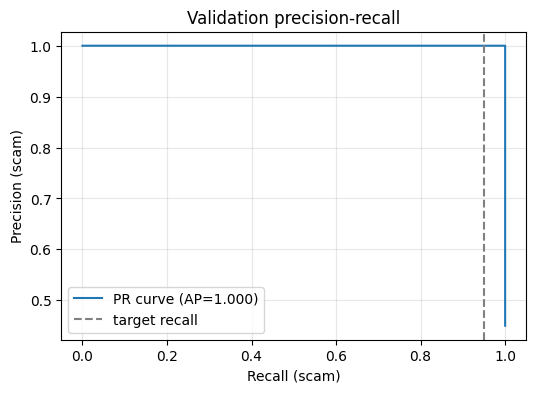

In [14]:
model.fit(train.TEXT, y_train)

def get_scores(m, texts):
    if hasattr(m, "predict_proba"):
        return m.predict_proba(texts)[:, 1]
    return m.decision_function(texts)

val_scores = get_scores(model, val.TEXT)
val_ap = average_precision_score(y_val, val_scores)
val_auc = roc_auc_score(y_val, val_scores)
print(f"Validation PR-AUC: {val_ap:.4f} | ROC-AUC: {val_auc:.4f}")

# Choose threshold: highest-precision threshold that still achieves scam recall >= target
TARGET_RECALL = 0.95
prec, rec, thr = precision_recall_curve(y_val, val_scores)
ok_idx = np.where(rec[:-1] >= TARGET_RECALL)[0]
if len(ok_idx):
    best_i = ok_idx[np.argmax(prec[:-1][ok_idx])]
    threshold = float(thr[best_i])
else:
    threshold = float(np.quantile(val_scores, 0.5))
    print("Target recall not reachable on validation; falling back to median threshold")
print(f"Chosen threshold: {threshold:.4f} (targets scam recall >= {TARGET_RECALL})")

plt.figure(figsize=(6, 4))
plt.plot(rec, prec, label=f"PR curve (AP={val_ap:.3f})")
plt.axvline(TARGET_RECALL, color="grey", ls="--", label="target recall")
plt.xlabel("Recall (scam)"); plt.ylabel("Precision (scam)"); plt.title("Validation precision-recall"); plt.legend(); plt.grid(alpha=.3); plt.show()

## 6. Final evaluation on the held-out test split (used once)

In [15]:
test_scores = get_scores(model, test.TEXT)
test_pred = (test_scores >= threshold).astype(int)
y_pred_lbl = np.where(test_pred == 1, "scam", "legitimate")

print("Test PR-AUC:", round(average_precision_score(y_test, test_scores), 4))
print("Test ROC-AUC:", round(roc_auc_score(y_test, test_scores), 4))
print(classification_report(test.BINARY_LABEL, y_pred_lbl, digits=4))

cm = confusion_matrix(test.BINARY_LABEL, y_pred_lbl, labels=["legitimate", "scam"])
tn, fp, fn, tp = cm.ravel()
print(f"Scam recall: {tp/(tp+fn):.4f} | Legitimate false-positive rate: {fp/(fp+tn):.4f}")
print(pd.DataFrame(cm, index=["true legit", "true scam"], columns=["pred legit", "pred scam"]))

Test PR-AUC: 1.0
Test ROC-AUC: 1.0
              precision    recall  f1-score   support

  legitimate     1.0000    1.0000    1.0000      2475
        scam     1.0000    1.0000    1.0000      2025

    accuracy                         1.0000      4500
   macro avg     1.0000    1.0000    1.0000      4500
weighted avg     1.0000    1.0000    1.0000      4500

Scam recall: 1.0000 | Legitimate false-positive rate: 0.0000
            pred legit  pred scam
true legit        2475          0
true scam            0       2025


## 7. Per-category results and error analysis

In [16]:
res = test.assign(pred=y_pred_lbl, score=test_scores)
res["correct"] = (res.pred == res.BINARY_LABEL)
per_cat = (res.groupby(["BINARY_LABEL", "CATEGORY"])
           .agg(n=("correct", "size"), accuracy=("correct", "mean"))
           .round(3))
per_cat

n  accuracy
BINARY_LABEL CATEGORY                        
legitimate   bank_link_hardneg  469       1.0
             bank_txn           506       1.0
             delivery           279       1.0
             otp                581       1.0
             personal           245       1.0
             service            274       1.0
             urgent_genuine     121       1.0
scam         apk_install        139       1.0
             callback_no_link   264       1.0
             job_fee            101       1.0
             kyc_phish          389       1.0
             otp_pin_request    391       1.0
             parcel_fee         245       1.0
             promo_spam         260       1.0
             reward_refund      236       1.0

In [17]:
# Most confident errors: scams predicted legit (missed) and legit predicted scam (false alarms)
missed = res[(res.BINARY_LABEL == "scam") & (res.pred == "legitimate")].sort_values("score").head(10)
false_alarm = res[(res.BINARY_LABEL == "legitimate") & (res.pred == "scam")].sort_values("score", ascending=False).head(10)
print("MISSED SCAMS:"); display(missed[["TEXT", "CATEGORY", "score"]])
print("FALSE ALARMS:"); display(false_alarm[["TEXT", "CATEGORY", "score"]])

MISSED SCAMS:


,TEXT,CATEGORY,score


FALSE ALARMS:


,TEXT,CATEGORY,score


## 8. Robustness checks

Perturb the test set in ways real SMS differs from templates, and check how much performance drops. A large drop from removing URLs or adding typos means the model relies on fragile cues.

In [18]:
def perturb_no_urls(t):
    return re.sub(r"(https?://\S+|www\.\S+|\b\S+\.(xyz|top|apk|club|click|online|site|in|com)\b|bit\.ly/\S+)", "[link]", t, flags=re.I)
def perturb_typos(t, seed=0):
    rng = np.random.default_rng(seed); w = list(t)
    for _ in range(max(1, len(w)//25)):
        if len(w) > 4:
            i = rng.integers(1, len(w)-1); w[i], w[i-1] = w[i-1], w[i]
    return "".join(w)
def perturb_upper(t): return t.upper()

variants = {
    "original": test.TEXT,
    "urls_removed": test.TEXT.map(perturb_no_urls),
    "typos_added": test.TEXT.map(perturb_typos),
    "all_caps": test.TEXT.map(perturb_upper),
}
rows = []
for name, texts in variants.items():
    s = get_scores(model, texts)
    p = (s >= threshold).astype(int)
    rows.append({"variant": name,
                 "PR-AUC": round(average_precision_score(y_test, s), 4),
                 "scam_recall": round(recall_score(y_test, p), 4),
                 "precision": round(precision_score(y_test, p, zero_division=0), 4),
                 "FPR_legit": round(((p == 1) & (y_test == 0)).sum() / (y_test == 0).sum(), 4)})
pd.DataFrame(rows)

,variant,PR-AUC,scam_recall,precision,FPR_legit
0,original,1.0,1.0000,1.0,0.0
1,urls_removed,1.0,1.0000,1.0,0.0
2,typos_added,1.0,0.9872,1.0,0.0
3,all_caps,1.0,1.0000,1.0,0.0


## 9. Save the model and its metadata

In [19]:
import os
os.makedirs("artifacts", exist_ok=True)
joblib.dump(model, "artifacts/sms_scam_classifier.joblib")
meta = {
    "model": chosen,
    "label_map": {"1": "scam", "0": "legitimate"},
    "threshold": threshold,
    "target_scam_recall": TARGET_RECALL,
    "validation_pr_auc": round(float(val_ap), 4),
    "test_pr_auc": round(float(average_precision_score(y_test, test_scores)), 4),
    "train_rows": len(train), "val_rows": len(val), "test_rows": len(test),
    "input": "raw SMS text (no preprocessing required)",
}
with open("artifacts/model_metadata.json", "w") as f: json.dump(meta, f, indent=2)
print(json.dumps(meta, indent=2))

# Quick inference check
samples = ["Your SBI KYC expired. Update now at http://sbi-kyc-verify.xyz/kyc or account blocked",
           "123456 is your OTP for login to HDFC net banking. Do not share it with anyone.",
           "Reached home safely, will talk tomorrow"]
for s_, sc in zip(samples, get_scores(model, samples)):
    print(("SCAM      " if sc >= threshold else "legitimate"), f"{sc:.3f}", "|", s_)

{
  "model": "NB_word_counts",
  "label_map": {
    "1": "scam",
    "0": "legitimate"
  },
  "threshold": 0.9999995991352031,
  "target_scam_recall": 0.95,
  "validation_pr_auc": 1.0,
  "test_pr_auc": 1.0,
  "train_rows": 21000,
  "val_rows": 4500,
  "test_rows": 4500,
  "input": "raw SMS text (no preprocessing required)"
}
SCAM       1.000 | Your SBI KYC expired. Update now at http://sbi-kyc-verify.xyz/kyc or account blocked
legitimate 0.000 | 123456 is your OTP for login to HDFC net banking. Do not share it with anyone.
legitimate 0.000 | Reached home safely, will talk tomorrow


## 10. Optional: external check on real SMS (UCI)
If you have the UCI SMS Spam Collection as `uci_sms.csv` with columns `LABEL` (`ham`/`spam`) and `TEXT`, this cell evaluates the model on real messages. Treat it as a generalization check, not as training data. Spam is mapped to scam under this product's definition.

In [27]:
import os
import pandas as pd

candidates = [
    r"sms+spam+collection\gSMSSpamCollection.csv",
    r"sms+spam+collection\SMSSpamCollection",
    "uci_sms.csv",
]
UCI_PATH = next((p for p in candidates if os.path.exists(p)), None)

if UCI_PATH is None:
    uci = None
    print("UCI file not found; checked:", candidates)
else:
    # Read the raw lines and split on the first tab or comma, so commas inside messages are safe
    rows = []
    with open(UCI_PATH, encoding="utf-8", errors="replace") as fh:
        for line in fh:
            line = line.rstrip("\n")
            if "\t" in line:
                lab, txt = line.split("\t", 1)
            elif line.startswith(("ham,", "spam,")):
                lab, txt = line.split(",", 1)
            else:
                continue
            rows.append((lab.strip().lower(), txt.strip()))
    uci = pd.DataFrame(rows, columns=["LABEL", "TEXT"])
    print("Loaded", UCI_PATH, "->", len(uci), "rows", uci.LABEL.value_counts().to_dict())

if uci is not None:
    y_uci = (uci.LABEL == "spam").astype(int)
    s_uci = get_scores(model, uci.TEXT)
    p_uci = (s_uci >= threshold).astype(int)
    print("UCI PR-AUC:", round(average_precision_score(y_uci, s_uci), 4))
    print("UCI scam recall:", round(recall_score(y_uci, p_uci), 4))
    print("UCI precision:", round(precision_score(y_uci, p_uci, zero_division=0), 4))
    print("UCI FPR on ham:", round(((p_uci == 1) & (y_uci == 0)).sum() / (y_uci == 0).sum(), 4))

Loaded sms+spam+collection\gSMSSpamCollection.csv -> 5574 rows {'ham': 4827, 'spam': 747}
UCI PR-AUC: 0.5115
UCI scam recall: 0.3574
UCI precision: 0.7255
UCI FPR on ham: 0.0209


## Notes for the report
- Model choice is based on CV PR-AUC on the training split, with the simplest model preferred within one standard deviation.
- The threshold is chosen on validation only; the test split is used once.
- Synthetic results overstate real performance. Report the UCI check separately and treat the gap as the key generalization result.
- The on-device pipeline (Raspberry Pi 5 CPU) should use the saved model directly; this classifier is independent of the Llama explanation component, which runs through ExecuTorch as a separate stage.

In [28]:
# seed_and_train.py
import re, numpy as np, pandas as pd
from sklearn.model_selection import train_test_split
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.pipeline import make_pipeline, make_union
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import average_precision_score, recall_score, precision_score

SEED = 42
rng = np.random.default_rng(SEED)
UCI_PATH = r"sms+spam+collection\gSMSSpamCollection.csv"  # adjust to your actual file

# ---- 1. Load real data (line-based parse, safe for commas) ----
rows = []
with open(UCI_PATH, encoding="utf-8", errors="replace") as fh:
    for line in fh:
        line = line.rstrip("\n")
        if "\t" in line:
            lab, txt = line.split("\t", 1)
        elif line.startswith(("ham,", "spam,")):
            lab, txt = line.split(",", 1)
        else:
            continue
        rows.append((txt.strip(), 1 if lab.strip().lower() == "spam" else 0))
real = pd.DataFrame(rows, columns=["TEXT", "y"]).drop_duplicates("TEXT").reset_index(drop=True)

# ---- 2. Fixed real splits: test is never used for tuning ----
r_pool, r_test = train_test_split(real, test_size=0.30, stratify=real.y, random_state=SEED)
r_train, r_val = train_test_split(r_pool, test_size=0.25, stratify=r_pool.y, random_state=SEED)

syn_train = pd.read_csv("binary_30k_train.csv")
syn_test = pd.read_csv("binary_30k_test.csv")
syn_train["y"] = (syn_train.BINARY_LABEL == "scam").astype(int)
syn_test["y"] = (syn_test.BINARY_LABEL == "scam").astype(int)

# ---- 3. Seeding: label-preserving augmentation of REAL train messages only ----
ABBR = {"you": "u", "your": "ur", "please": "pls", "for": "4", "are": "r", "to": "2"}
def augment(text):
    t = text
    r = rng.random()
    if r < 0.25:
        t = re.sub(r"\b(\w+)\b", lambda m: ABBR.get(m.group(1).lower(), m.group(1)), t)
    elif r < 0.45:
        w = list(t)
        if len(w) > 8:
            i = rng.integers(2, len(w) - 2); w[i], w[i + 1] = w[i + 1], w[i]
        t = "".join(w)
    elif r < 0.6:
        t = t.upper() if rng.random() < 0.5 else t.lower()
    elif r < 0.75:
        t = re.sub(r"\d{6,}", lambda m: "".join(rng.choice(list("0123456789"), len(m.group(0)))), t)
    else:
        t = t + rng.choice([" :)", " pls reply", " thx", " 2day"])
    return t

aug_rows = []
for _ in range(2):                       # two augmented copies per real train message
    for txt, y in zip(r_train.TEXT, r_train.y):
        aug_rows.append((augment(txt), y))
r_aug = pd.DataFrame(aug_rows, columns=["TEXT", "y"])

# ---- 4. Model and helpers ----
def make_model():
    return make_pipeline(
        make_union(
            TfidfVectorizer(analyzer="char_wb", ngram_range=(2, 5), min_df=2, sublinear_tf=True),
            TfidfVectorizer(ngram_range=(1, 2), min_df=2, sublinear_tf=True),
        ),
        LogisticRegression(max_iter=3000, C=3, class_weight="balanced"),
    )

def fit(texts, y, weights=None):
    m = make_model()
    m.fit(texts, y, logisticregression__sample_weight=weights)
    return m

def threshold_for_recall(y, s, target=0.90):
    order = np.sort(np.unique(s))[::-1]
    for t in order:                      # highest threshold that still meets the target
        if recall_score(y, (s >= t).astype(int)) >= target:
            return float(t)
    return float(order[-1])

def evaluate(m, texts, y, thr):
    s = m.predict_proba(texts)[:, 1]
    p = (s >= thr).astype(int)
    return {"PR_AUC": round(average_precision_score(y, s), 4),
            "scam_recall": round(recall_score(y, p), 4),
            "precision": round(precision_score(y, p, zero_division=0), 4),
            "FPR_legit": round(((p == 1) & (y == 0)).sum() / (y == 0).sum(), 4)}

# ---- 5. Ablation ----
REAL_WEIGHT = 5.0
configs = {}

# A: synthetic only
mA = fit(syn_train.TEXT, syn_train.y)
configs["A_synthetic_only"] = (mA, None)

# B: real train only
mB = fit(r_train.TEXT, r_train.y)
configs["B_real_only"] = (mB, None)

# C: synthetic + real (real upweighted)
C_texts = pd.concat([syn_train.TEXT, r_train.TEXT], ignore_index=True)
C_y = pd.concat([syn_train.y, r_train.y], ignore_index=True)
C_w = np.concatenate([np.ones(len(syn_train)), np.full(len(r_train), REAL_WEIGHT)])
configs["C_mixed"] = (fit(C_texts, C_y, C_w), None)

# D: synthetic + real + augmented real seeds
D_texts = pd.concat([C_texts, r_aug.TEXT], ignore_index=True)
D_y = pd.concat([C_y, r_aug.y], ignore_index=True)
D_w = np.concatenate([C_w, np.full(len(r_aug), REAL_WEIGHT)])
configs["D_mixed_augmented"] = (fit(D_texts, D_y, D_w), None)

rows = []
for name, (m, _) in configs.items():
    # threshold chosen on REAL validation, not on synthetic
    thr = threshold_for_recall(r_val.y.values, m.predict_proba(r_val.TEXT)[:, 1], target=0.90)
    real_test = evaluate(m, r_test.TEXT, r_test.y.values, thr)
    syn_eval = evaluate(m, syn_test.TEXT, syn_test.y.values, thr)
    rows.append({"config": name, "threshold": round(thr, 4),
                 **{f"real_{k}": v for k, v in real_test.items()},
                 **{f"synth_{k}": v for k, v in syn_eval.items()}})

results = pd.DataFrame(rows)
print(results.to_string(index=False))
results.to_csv("seeding_ablation.csv", index=False)

           config  threshold  real_PR_AUC  real_scam_recall  real_precision  real_FPR_legit  synth_PR_AUC  synth_scam_recall  synth_precision  synth_FPR_legit
 A_synthetic_only     0.0684       0.4937            0.9067          0.1938          0.5373        1.0000             1.0000           0.9995           0.0004
      B_real_only     0.8248       0.9936            0.8601          1.0000          0.0000        0.6421             0.1872           0.7137           0.0614
          C_mixed     0.8240       0.9828            0.8601          0.9940          0.0007        1.0000             1.0000           1.0000           0.0000
D_mixed_augmented     0.9206       0.9879            0.8290          1.0000          0.0000        1.0000             0.9995           1.0000           0.0000


In [29]:
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.metrics.pairwise import cosine_similarity
import numpy as np

vec = TfidfVectorizer(analyzer="char_wb", ngram_range=(3, 5)).fit(r_pool.TEXT)
S = cosine_similarity(vec.transform(r_test.TEXT), vec.transform(r_train.TEXT))
best = S.max(axis=1)
print("test messages with a train neighbour >0.9 similarity:", (best > 0.9).mean().round(3))
print("test messages with a train neighbour >0.8 similarity:", (best > 0.8).mean().round(3))

test messages with a train neighbour >0.9 similarity: 0.019
test messages with a train neighbour >0.8 similarity: 0.037


In [30]:
# final_model.py
import json, re, os
import numpy as np, pandas as pd, joblib
from sklearn.model_selection import train_test_split
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.pipeline import make_pipeline, make_union
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import average_precision_score, recall_score, precision_score, confusion_matrix

SEED = 42
TARGET_RECALL = 0.90
REAL_WEIGHT = 5.0
UCI_PATH = r"sms+spam+collection\gSMSSpamCollection.csv"   # adjust to your file
OUT_DIR = "artifacts"
os.makedirs(OUT_DIR, exist_ok=True)

# ---------- 1. Real data (UCI), line-based parse ----------
rows = []
with open(UCI_PATH, encoding="utf-8", errors="replace") as fh:
    for line in fh:
        line = line.rstrip("\n")
        if "\t" in line:
            lab, txt = line.split("\t", 1)
        elif line.startswith(("ham,", "spam,")):
            lab, txt = line.split(",", 1)
        else:
            continue
        rows.append((txt.strip(), 1 if lab.strip().lower() == "spam" else 0))
real = pd.DataFrame(rows, columns=["TEXT", "y"]).drop_duplicates("TEXT").reset_index(drop=True)

# ---------- 2. Fixed splits (same seed as the ablation) ----------
r_pool, r_test = train_test_split(real, test_size=0.30, stratify=real.y, random_state=SEED)
r_train, r_val = train_test_split(r_pool, test_size=0.25, stratify=r_pool.y, random_state=SEED)

# Drop test messages that have a close twin in training (similarity > 0.8)
from sklearn.feature_extraction.text import TfidfVectorizer as _TV
from sklearn.metrics.pairwise import cosine_similarity
_v = _TV(analyzer="char_wb", ngram_range=(3, 5)).fit(r_train.TEXT)
keep = cosine_similarity(_v.transform(r_test.TEXT), _v.transform(r_train.TEXT)).max(axis=1) <= 0.8
r_test = r_test[keep].reset_index(drop=True)

syn_train = pd.read_csv("binary_30k_train.csv")
syn_test  = pd.read_csv("binary_30k_test.csv")
syn_train["y"] = (syn_train.BINARY_LABEL == "scam").astype(int)
syn_test["y"]  = (syn_test.BINARY_LABEL == "scam").astype(int)

# ---------- 3. Final training data: synthetic + real (real upweighted) ----------
X_train = pd.concat([syn_train.TEXT, r_train.TEXT], ignore_index=True)
y_train = pd.concat([syn_train.y, r_train.y], ignore_index=True)
w_train = np.concatenate([np.ones(len(syn_train)), np.full(len(r_train), REAL_WEIGHT)])

model = make_pipeline(
    make_union(
        TfidfVectorizer(analyzer="char_wb", ngram_range=(2, 5), min_df=2, sublinear_tf=True),
        TfidfVectorizer(ngram_range=(1, 2), min_df=2, sublinear_tf=True),
    ),
    LogisticRegression(max_iter=3000, C=3, class_weight="balanced"),
)
model.fit(X_train, y_train, logisticregression__sample_weight=w_train)

# ---------- 4. Threshold chosen on REAL validation only ----------
s_val = model.predict_proba(r_val.TEXT)[:, 1]
def threshold_for_recall(y, s, target):
    for t in np.sort(np.unique(s))[::-1]:
        if recall_score(y, (s >= t).astype(int)) >= target:
            return float(t)
    return float(s.min())
threshold = threshold_for_recall(r_val.y.values, s_val, TARGET_RECALL)
print(f"Threshold on real validation (recall >= {TARGET_RECALL}): {threshold:.4f}")

# ---------- 5. Final one-time evaluation ----------
def report(name, texts, y):
    s = model.predict_proba(texts)[:, 1]
    p = (s >= threshold).astype(int)
    tn, fp, fn, tp = confusion_matrix(y, p, labels=[0, 1]).ravel()
    out = {"n": len(y), "PR_AUC": round(average_precision_score(y, s), 4),
           "scam_recall": round(tp / (tp + fn), 4),
           "precision": round(precision_score(y, p, zero_division=0), 4),
           "FPR_legit": round(fp / (fp + tn), 4)}
    print(name, out)
    return out

results = {
    "real_test_UCI": report("real test (UCI)", r_test.TEXT, r_test.y.values),
    "synthetic_test": report("synthetic test", syn_test.TEXT, syn_test.y.values),
}

# ---------- 6. Save model and metadata ----------
joblib.dump(model, f"{OUT_DIR}/final_scam_classifier.joblib")
meta = {
    "model_name": "final_scam_classifier",
    "version": "1.0",
    "task": "binary SMS classification: scam vs legitimate",
    "label_map": {"1": "scam", "0": "legitimate"},
    "input": "raw SMS text, no preprocessing needed",
    "architecture": "TF-IDF char_wb(2-5) + word(1-2) -> logistic regression (C=3, balanced)",
    "training_data": {"synthetic_train_rows": int(len(syn_train)),
                      "real_train_rows": int(len(r_train)), "real_weight": REAL_WEIGHT},
    "threshold": threshold,
    "threshold_selected_on": "real validation split, scam recall >= 0.90",
    "test_results": results,
    "seed": SEED,
    "note": "Real test set was used once for reporting. Estimates on real Indian SMS are not yet available.",
}
with open(f"{OUT_DIR}/final_model_metadata.json", "w") as f:
    json.dump(meta, f, indent=2)
print("Saved:", f"{OUT_DIR}/final_scam_classifier.joblib", "and final_model_metadata.json")

# ---------- 7. Inference helper for the app ----------
def classify(messages, model=model, threshold=threshold):
    s = model.predict_proba(messages)[:, 1]
    return [{"label": "scam" if v >= threshold else "legitimate", "score": round(float(v), 4)} for v in s]

if __name__ == "__main__":
    demo = ["Your SBI KYC expired. Update now at http://sbi-kyc-verify.xyz or account blocked",
            "Reached home safely, will talk tomorrow"]
    for m, r in zip(demo, classify(demo)):
        print(r, "|", m)

Threshold on real validation (recall >= 0.9): 0.8240
real test (UCI) {'n': 1487, 'PR_AUC': 0.9721, 'scam_recall': np.float64(0.8125), 'precision': 0.9915, 'FPR_legit': np.float64(0.0007)}
synthetic test {'n': 4500, 'PR_AUC': 1.0, 'scam_recall': np.float64(1.0), 'precision': 1.0, 'FPR_legit': np.float64(0.0)}
Saved: artifacts/final_scam_classifier.joblib and final_model_metadata.json
{'label': 'scam', 'score': 0.9996} | Your SBI KYC expired. Update now at http://sbi-kyc-verify.xyz or account blocked
{'label': 'legitimate', 'score': 0.0019} | Reached home safely, will talk tomorrow


In [31]:
# export_classifier.py
# Exports artifacts/final_scam_classifier.joblib to assets/scam_model.json
import json, joblib, numpy as np, os

MODEL = "artifacts/final_scam_classifier.joblib"
META = "artifacts/final_model_metadata.json"
OUT = "android_app/app/src/main/assets/scam_model.json"

model = joblib.load(MODEL)
meta = json.load(open(META))
union = model.steps[0][1]
lr = model.steps[1][1]

def block(vec):
    # Check the vectorizer settings the Kotlin code relies on
    assert vec.lowercase and vec.sublinear_tf and vec.norm == "l2" and vec.use_idf
    assert vec.strip_accents is None and vec.binary is False
    return {
        "analyzer": vec.analyzer,                # "char_wb" or "word"
        "ngram_min": vec.ngram_range[0],
        "ngram_max": vec.ngram_range[1],
        "vocabulary": {k: int(v) for k, v in vec.vocabulary_.items()},
        "idf": [float(x) for x in vec.idf_],
        "token_pattern": vec.token_pattern,
    }

blocks = [block(t) for _, t in union.transformer_list]
offsets = np.cumsum([0] + [len(b["idf"]) for b in blocks])

payload = {
    "threshold": meta["threshold"],
    "intercept": float(lr.intercept_[0]),
    "coef": [float(x) for x in lr.coef_[0]],
    "blocks": blocks,          # order matters: concatenated in this order
    "block_offsets": [int(x) for x in offsets],
}
os.makedirs(os.path.dirname(OUT), exist_ok=True)
with open(OUT, "w", encoding="utf-8") as f:
    json.dump(payload, f, ensure_ascii=False)
print("wrote", OUT, "size MB:", round(os.path.getsize(OUT) / 1e6, 2), "features:", offsets[-1])

wrote android_app/app/src/main/assets/scam_model.json size MB: 4.9 features: 86549


In [32]:
# check_reference.py  (mirrors the Kotlin logic line by line)
import math, re, json, numpy as np, pandas as pd
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.pipeline import make_pipeline, make_union
from sklearn.linear_model import LogisticRegression

def char_wb_terms(text, n_min, n_max):
    out = []
    for word in text.lower().split():          # sklearn splits on whitespace
        w = " " + word + " "                   # pad each word with one space
        for n in range(n_min, n_max + 1):
            for i in range(len(w) - n + 1):
                out.append(w[i:i + n])
    return out

def word_terms(text, pattern=r"(?u)\b\w\w+\b"):
    return re.findall(pattern, text.lower())

def ngrams(tokens, n_min, n_max):
    out = []
    for n in range(n_min, n_max + 1):
        for i in range(len(tokens) - n + 1):
            out.append(" ".join(tokens[i:i + n]))
    return out

def vectorize_block(block, text):
    if block["analyzer"] == "char_wb":
        terms = char_wb_terms(text, block["ngram_min"], block["ngram_max"])
    else:
        terms = ngrams(word_terms(text, block["token_pattern"]), block["ngram_min"], block["ngram_max"])
    counts = {}
    for t in terms:
        if t in block["vocabulary"]:
            counts[t] = counts.get(t, 0) + 1
    size = len(block["idf"])
    vec = np.zeros(size)
    for t, c in counts.items():
        j = block["vocabulary"][t]
        vec[j] = (1 + math.log(c)) * block["idf"][j]     # sublinear tf * idf
    norm = np.linalg.norm(vec)
    return vec / norm if norm > 0 else vec              # l2 per block

def score_reference(payload, text):
    x = np.concatenate([vectorize_block(b, text) for b in payload["blocks"]])
    z = payload["intercept"] + float(np.dot(payload["coef"], x))
    return 1 / (1 + math.exp(-z))

if __name__ == "__main__":
    syn = pd.read_csv("binary_30k_train.csv").sample(3000, random_state=0)
    y = (syn.BINARY_LABEL == "scam").astype(int)
    model = make_pipeline(
        make_union(TfidfVectorizer(analyzer="char_wb", ngram_range=(2, 5), min_df=2, sublinear_tf=True),
                   TfidfVectorizer(ngram_range=(1, 2), min_df=2, sublinear_tf=True)),
        LogisticRegression(max_iter=3000, C=3, class_weight="balanced"))
    model.fit(syn.TEXT, y)

    union, lr = model.steps[0][1], model.steps[1][1]
    blocks = []
    for _, t in union.transformer_list:
        blocks.append({"analyzer": t.analyzer, "ngram_min": t.ngram_range[0], "ngram_max": t.ngram_range[1],
                       "vocabulary": {k: int(v) for k, v in t.vocabulary_.items()},
                       "idf": [float(v) for v in t.idf_], "token_pattern": t.token_pattern})
    payload = {"intercept": float(lr.intercept_[0]), "coef": [float(v) for v in lr.coef_[0]], "blocks": blocks}

    test = pd.read_csv("binary_30k_test.csv").sample(300, random_state=1).TEXT.tolist()
    sk = model.predict_proba(test)[:, 1]
    ref = np.array([score_reference(payload, t) for t in test])
    print("max abs difference:", float(np.max(np.abs(sk - ref))))

max abs difference: 2.220446049250313e-16


In [34]:
# risk_advisor.py
import json, re
import numpy as np, joblib

CLF_PATH = "artifacts/final_scam_classifier.joblib"
META_PATH = "artifacts/final_model_metadata.json"

class ScamClassifier:
    def __init__(self, path=CLF_PATH, meta_path=META_PATH):
        self.model = joblib.load(path)
        with open(meta_path) as f:
            self.meta = json.load(f)
        self.threshold = self.meta["threshold"]
        self.vec = self.model.steps[0][1]   # FeatureUnion of TF-IDF transformers
        self.clf = self.model.steps[1][1]   # LogisticRegression

    def score(self, text):
        return float(self.model.predict_proba([text])[0, 1])

    def explain(self, text, k=5):
        """Words/n-grams that pushed the score up (scam) or down (legitimate)."""
        x = self.vec.transform([text]).toarray()[0]
        contrib = x * self.clf.coef_[0]
        names = [n.split("__")[-1] for n in self.vec.get_feature_names_out()]
        idx = np.argsort(-np.abs(contrib))
        seen, terms = set(), []
        for i in idx:
            if contrib[i] == 0 or names[i] in seen:
                continue
            seen.add(names[i])
            terms.append({"term": names[i], "push": "scam" if contrib[i] > 0 else "legitimate"})
            if len(terms) == k:
                break
        return terms

    def urls(self, text):
        return re.findall(r"(?:https?://|www\.)\S+|\b[\w-]+\.(?:xyz|top|apk|club|click|online|site)\b|bit\.ly/\S+", text, re.I)

    def assess(self, text):
        s = self.score(text)
        return {
            "message": text,
            "label": "scam" if s >= self.threshold else "legitimate",
            "score": round(s, 4),
            "threshold": round(self.threshold, 4),
            "top_terms": self.explain(text),
            "urls": self.urls(text),
        }


# ---------- Llama advisor ----------
SYSTEM = (
    "You are a security assistant that explains SMS scam decisions to non-expert users. "
    "The classifier has already made the decision; do not change it. "
    "Explain in plain language, in at most 5 short sentences, why the message is or is not likely a scam. "
    "Then give 2 to 3 concrete actions the user should take. Never ask for OTPs, PINs or card details. "
    "Do not invent facts about the sender."
)

def build_prompt(a):
    terms = ", ".join(f'"{t["term"]}" ({t["push"]})' for t in a["top_terms"]) or "none"
    urls = ", ".join(a["urls"]) or "none"
    return (
        f"Message: {a['message']}\n"
        f"Classifier decision: {a['label']} (scam score {a['score']}, threshold {a['threshold']})\n"
        f"Words that influenced the decision: {terms}\n"
        f"Links found: {urls}\n"
        "Write the explanation and actions for the user."
    )

def template_advice(a):
    """Fallback used when no LLM is available. Keeps the app working."""
    if a["label"] == "scam":
        return ("This message looks like a scam. It may be trying to get your money, login details, "
                "or OTP. Do not click any link, call the number, or share codes. Block the sender and "
                "check your bank through its official app or website.")
    return ("This message looks legitimate. Still, if it asks for an OTP, PIN, or payment you did not "
            "expect, do not act on it, and contact the organisation through its official channel.")

class DevLlamaBackend:
    """Development backend using Hugging Face transformers with a Llama-family instruct model."""
    def __init__(self, model_id="meta-llama/Llama-3.2-1B-Instruct", max_new_tokens=200):
        from transformers import AutoTokenizer, AutoModelForCausalLM
        self.tok = AutoTokenizer.from_pretrained(model_id)
        self.model = AutoModelForCausalLM.from_pretrained(model_id, torch_dtype="auto")
        self.max_new_tokens = max_new_tokens

    def generate(self, system, user):
        msgs = [{"role": "system", "content": system}, {"role": "user", "content": user}]
        ids = self.tok.apply_chat_template(msgs, add_generation_prompt=True, return_tensors="pt")
        out = self.model.generate(ids, max_new_tokens=self.max_new_tokens, do_sample=False)
        return self.tok.decode(out[0][ids.shape[1]:], skip_special_tokens=True).strip()

class RiskAdvisor:
    def __init__(self, backend=None):
        self.clf = ScamClassifier()
        self.backend = backend   # None -> template fallback

    def advise(self, text):
        a = self.clf.assess(text)
        if self.backend is not None:
            try:
                a["explanation"] = self.backend.generate(SYSTEM, build_prompt(a))
                a["advice_source"] = "llama"
                return a
            except Exception as e:
                a["advice_error"] = str(e)
        a["explanation"] = template_advice(a)
        a["advice_source"] = "template"
        return a

if __name__ == "__main__":
    import sys
    backend = None
    if "--llama" in sys.argv:
        backend = DevLlamaBackend()
    advisor = RiskAdvisor(backend)
    samples = [
        "Your SBI KYC expired. Update now at http://sbi-kyc-verify.xyz or account will be blocked",
        "123456 is your OTP for login to HDFC net banking. Do not share it with anyone.",
        "Reached home safely, will talk tomorrow",
    ]
    for s in samples:
        r = advisor.advise(s)
        print(f"\n[{r['label'].upper()}  score={r['score']}]  {r['message']}")
        print("Why:", ", ".join(f"{t['term']}->{t['push']}" for t in r["top_terms"]))
        print("Advice:", r["explanation"])
        print("Source:", r["advice_source"])


[SCAM  score=0.9996]  Your SBI KYC expired. Update now at http://sbi-kyc-verify.xyz or account will be blocked
Why: now->scam, http->scam, account->scam, kyc->scam, verify->scam
Advice: This message looks like a scam. It may be trying to get your money, login details, or OTP. Do not click any link, call the number, or share codes. Block the sender and check your bank through its official app or website.
Source: template

[LEGITIMATE  score=0.0083]  123456 is your OTP for login to HDFC net banking. Do not share it with anyone.
Why: to->scam, not share->legitimate, do->legitimate, is your->legitimate, with->scam
Advice: This message looks legitimate. Still, if it asks for an OTP, PIN, or payment you did not expect, do not act on it, and contact the organisation through its official channel.
Source: template

[LEGITIMATE  score=0.0019]  Reached home safely, will talk tomorrow
Why: tomorrow->legitimate, reached->legitimate, talk->legitimate, ly->scam, me ->legitimate
Advice: This message 